# Model Training & Evaluation

**Energy App Review Sentiment Analysis and Rating Prediction**

This notebook documents and verifies the saved final models trained by `src/train.py`. It reads the existing data, fitted models, and reports rather than launching a separate training process. This keeps the notebook in agreement with the reproducible command-line workflow.

**The two prediction tasks:** sentiment (**Negative**, **Neutral**, **Positive**) and the original **1–5 star rating**. Sentiment labels are inferred from star ratings and are **not independently human-annotated**.

## 1. Load dependencies and use the project root

Run the notebook from the existing repository in VS Code. It handles a working directory of either the project root or `notebooks/`.

In [1]:
from pathlib import Path
import os
import sys

import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sklearn.metrics import classification_report, confusion_matrix

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/train.py").exists(), f"Cannot find project root from {Path.cwd()}"
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.train import load_dataset, make_partitions, metrics

print("Project root:", ROOT)
print("Analysis uses saved models and does not overwrite any training output.")

Project root: C:\Users\HP\Desktop\nlp-yelp-sentiment-rating-prediction
Analysis uses saved models and does not overwrite any training output.


## 2. Dataset overview

The dataset contains English-language reviews collected from Google Play and Apple's App Store. Ambiguous pairs with identical review text but conflicting star ratings were removed during preprocessing.

In [2]:
df, review_groups = load_dataset()
print(f"Processed reviews: {len(df):,}")
print(f"Applications: {df['app_name'].nunique()}")
print("Platforms:")
display(df['platform'].value_counts().rename_axis('platform').reset_index(name='reviews'))
print("Ratings:")
display(df['rating'].value_counts().sort_index().rename_axis('stars').reset_index(name='reviews'))
print("Sentiment labels:")
display(df['sentiment'].value_counts().rename_axis('sentiment').reset_index(name='reviews'))
assert len(df) == 70994, 'Dataset size differs from the currently validated 70,994; rerun the batch audit.'

Processed reviews: 70,994
Applications: 19
Platforms:


,platform,reviews
0,google_play,60766
1,apple_app_store,10228


Ratings:


,stars,reviews
0,1,29951
1,2,6383
2,3,5539
3,4,6354
4,5,22767


Sentiment labels:


,sentiment,reviews
0,Negative,36334
1,Positive,29121
2,Neutral,5539


## 3. Leakage-aware train / validation / test split

The source training script uses a stratified, **group-aware** split with a shared partition for both tasks. Grouping by normalized cleaned text keeps identical processed review text on one side of the split. It does not guarantee that all paraphrases are removed.

All model selection was carried out on the validation set. The test set was held back until after the final candidate was selected and refitted on the training and validation partitions.

In [3]:
train_idx, validation_idx, test_idx = make_partitions(df, review_groups)
partition_rows = [
    {"partition": name, "reviews": len(idx), "share_pct": round(100 * len(idx) / len(df), 2)}
    for name, idx in [
        ("Train", train_idx), ("Validation", validation_idx), ("Test", test_idx)
    ]
]
display(pd.DataFrame(partition_rows))
g = [set(review_groups[idx]) for idx in (train_idx, validation_idx, test_idx)]
assert not (g[0]&g[1] or g[0]&g[2] or g[1]&g[2]), "Identical-text groups overlap"
assert len(train_idx)+len(validation_idx)+len(test_idx)==len(df)
print("No normalized-text group overlaps between partitions.")

Train      : 42,596 reviews | ratings {1: 17970, 2: 3830, 3: 3324, 4: 3812, 5: 13660}
Validation : 14,199 reviews | ratings {1: 5990, 2: 1277, 3: 1107, 4: 1271, 5: 4554}
Test       : 14,199 reviews | ratings {1: 5991, 2: 1276, 3: 1108, 4: 1271, 5: 4553}


,partition,reviews,share_pct
0,Train,42596,60.0
1,Validation,14199,20.0
2,Test,14199,20.0


No normalized-text group overlaps between partitions.


## 4. Model comparisons on validation data

These tables were generated by `src/train.py` using **validation data only**, not the held-out test data. Candidate selection is based on Macro F1, giving each class equal weight regardless of its frequency.

In [4]:
sentiment_candidates = pd.read_csv(ROOT / "reports/final_baseline_vs_tuned_model_comparison.csv")
rating_candidates = pd.read_csv(ROOT / "reports/final_rating_baseline_vs_tuned_comparison.csv")

cols = ['stage', 'model_name', 'accuracy', 'macro_f1', 'weighted_f1']
print("Sentiment candidates — validation")
display(sentiment_candidates[cols].sort_values('macro_f1', ascending=False).reset_index(drop=True))
print("Rating candidates — validation")
display(rating_candidates[cols + ['mean_absolute_error']].sort_values('macro_f1', ascending=False).reset_index(drop=True))
assert set(sentiment_candidates['stage']).issuperset({'Selected'})
assert set(rating_candidates['stage']).issuperset({'Selected'})

Sentiment candidates — validation


,stage,model_name,accuracy,macro_f1,weighted_f1
0,Selected,TF-IDF + LinearSVC,0.8176,0.6672,0.8200
1,Baseline,CountVectorizer + Naive Bayes,0.8067,0.6645,0.8104
2,Candidate,CountVectorizer + Tuned Naive Bayes,0.8062,0.6644,0.8103
3,Candidate,Character TF-IDF + Logistic Regression,0.7546,0.6522,0.7877


Rating candidates — validation


,stage,model_name,accuracy,macro_f1,weighted_f1,mean_absolute_error
0,Selected,CountVectorizer + Naive Bayes,0.6729,0.4737,0.6615,0.5680
1,Candidate,TF-IDF + LinearSVC,0.6534,0.4713,0.6562,0.5693
2,Candidate,Character TF-IDF + Logistic Regression,0.5974,0.4700,0.6314,0.6121
3,Candidate,CountVectorizer + Logistic Regression,0.5915,0.4552,0.6225,0.6360


## 5. Final models and vectorization settings

Both saved objects are full scikit-learn pipelines (vectorizer + classifier). The final models are stored locally and excluded from GitHub because they can be rebuilt by running `python src/train.py`.

In [5]:
sentiment_path = ROOT / "models/final_sentiment_model.pkl"
rating_path = ROOT / "models/final_rating_model.pkl"
for p in (sentiment_path, rating_path):
    assert p.is_file(), f"Missing trained model: {p}. Run python src/train.py."

sentiment_model = joblib.load(sentiment_path)
rating_model = joblib.load(rating_path)
rows = []
for task, pipe in [("Sentiment", sentiment_model), ("Rating", rating_model)]:
    vect = pipe.named_steps['vectorizer']
    clf = pipe.named_steps['model']
    rows.append({
        'task': task,
        'vectorizer': type(vect).__name__,
        'model': type(clf).__name__,
        'analyzer': vect.get_params().get('analyzer', 'word'),
        'ngram_range': str(vect.get_params().get('ngram_range')),
        'max_features': vect.get_params().get('max_features'),
    })
display(pd.DataFrame(rows))

,task,vectorizer,model,analyzer,ngram_range,max_features
0,Sentiment,TfidfVectorizer,LinearSVC,word,"(1, 2)",10000
1,Rating,CountVectorizer,MultinomialNB,word,"(1, 2)",5000


## 6. Held-out test evaluation

The following predictions recompute test metrics using the **saved final models** and the exact test indices reconstructed by `src.train.make_partitions`. The result must match the existing `reports/final_model_summary.csv` to rounding precision.

In [6]:
X = df['clean_review_text'].to_numpy()
pred_sentiment = sentiment_model.predict(X[test_idx])
pred_rating = rating_model.predict(X[test_idx])

sentiment_metrics = metrics(df['sentiment'].to_numpy()[test_idx], pred_sentiment)
rating_metrics = metrics(df['rating'].to_numpy()[test_idx], pred_rating, rating=True)

recomputed = pd.DataFrame([
    {'task': 'sentiment', **sentiment_metrics},
    {'task': 'rating', **rating_metrics},
]).set_index('task')
display(recomputed.round(4))

saved = pd.read_csv(ROOT / 'reports/final_model_summary.csv').set_index('task')
for task in ['sentiment', 'rating']:
    for metric_name in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']:
        diff = abs(float(recomputed.loc[task, metric_name]) - float(saved.loc[task, metric_name]))
        assert diff < 0.00011, f'{task} {metric_name} differs from saved report: {diff}'
assert abs(rating_metrics['mean_absolute_error'] - float(saved.loc['rating','mae'])) < 0.00011
assert (saved['train_count']==len(train_idx)).all()
assert (saved['validation_count']==len(validation_idx)).all()
assert (saved['test_count']==len(test_idx)).all()
print('PASS: Saved model predictions, held-out metrics, and partition sizes match the final report.')

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_absolute_error,within_one_star_accuracy
task,,,,,,,
sentiment,0.8083,0.6569,0.6618,0.6583,0.8140,NaN,NaN
rating,0.6766,0.4877,0.4761,0.4800,0.6651,0.565,0.8593


PASS: Saved model predictions, held-out metrics, and partition sizes match the final report.


## 7. Class-level performance

Confusion matrices and classification reports show where the overall accuracy hides weaker results. In particular, **neutral sentiment** and the **middle star ratings** have fewer examples than extreme ratings.

In [7]:
print('Sentiment classification report — held-out test')
print(classification_report(df['sentiment'].to_numpy()[test_idx], pred_sentiment,
                            labels=['Negative','Neutral','Positive'], zero_division=0))
print('Rating classification report — held-out test')
print(classification_report(df['rating'].to_numpy()[test_idx], pred_rating,
                            labels=[1,2,3,4,5], zero_division=0))

Sentiment classification report — held-out test
              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86      7267
     Neutral       0.23      0.28      0.25      1108
    Positive       0.89      0.85      0.87      5824

    accuracy                           0.81     14199
   macro avg       0.66      0.66      0.66     14199
weighted avg       0.82      0.81      0.81     14199

Rating classification report — held-out test
              precision    recall  f1-score   support

           1       0.75      0.82      0.78      5991
           2       0.26      0.19      0.22      1276
           3       0.25      0.24      0.25      1108
           4       0.35      0.29      0.32      1271
           5       0.82      0.84      0.83      4553

    accuracy                           0.68     14199
   macro avg       0.49      0.48      0.48     14199
weighted avg       0.66      0.68      0.67     14199



Sentiment confusion matrix


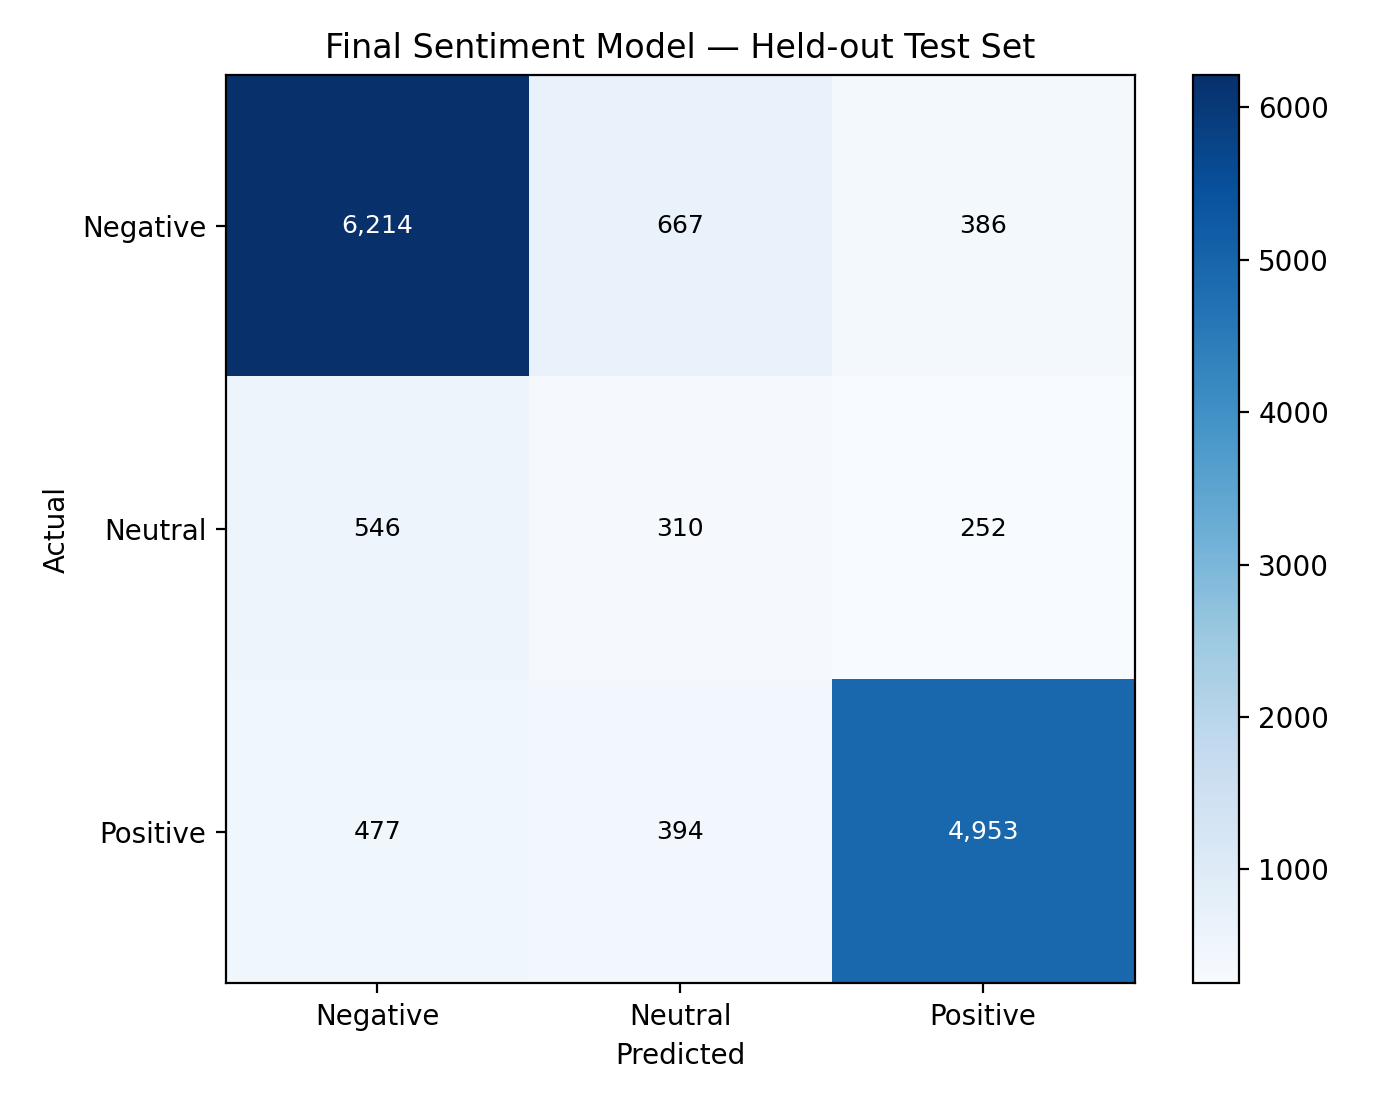

Rating confusion matrix


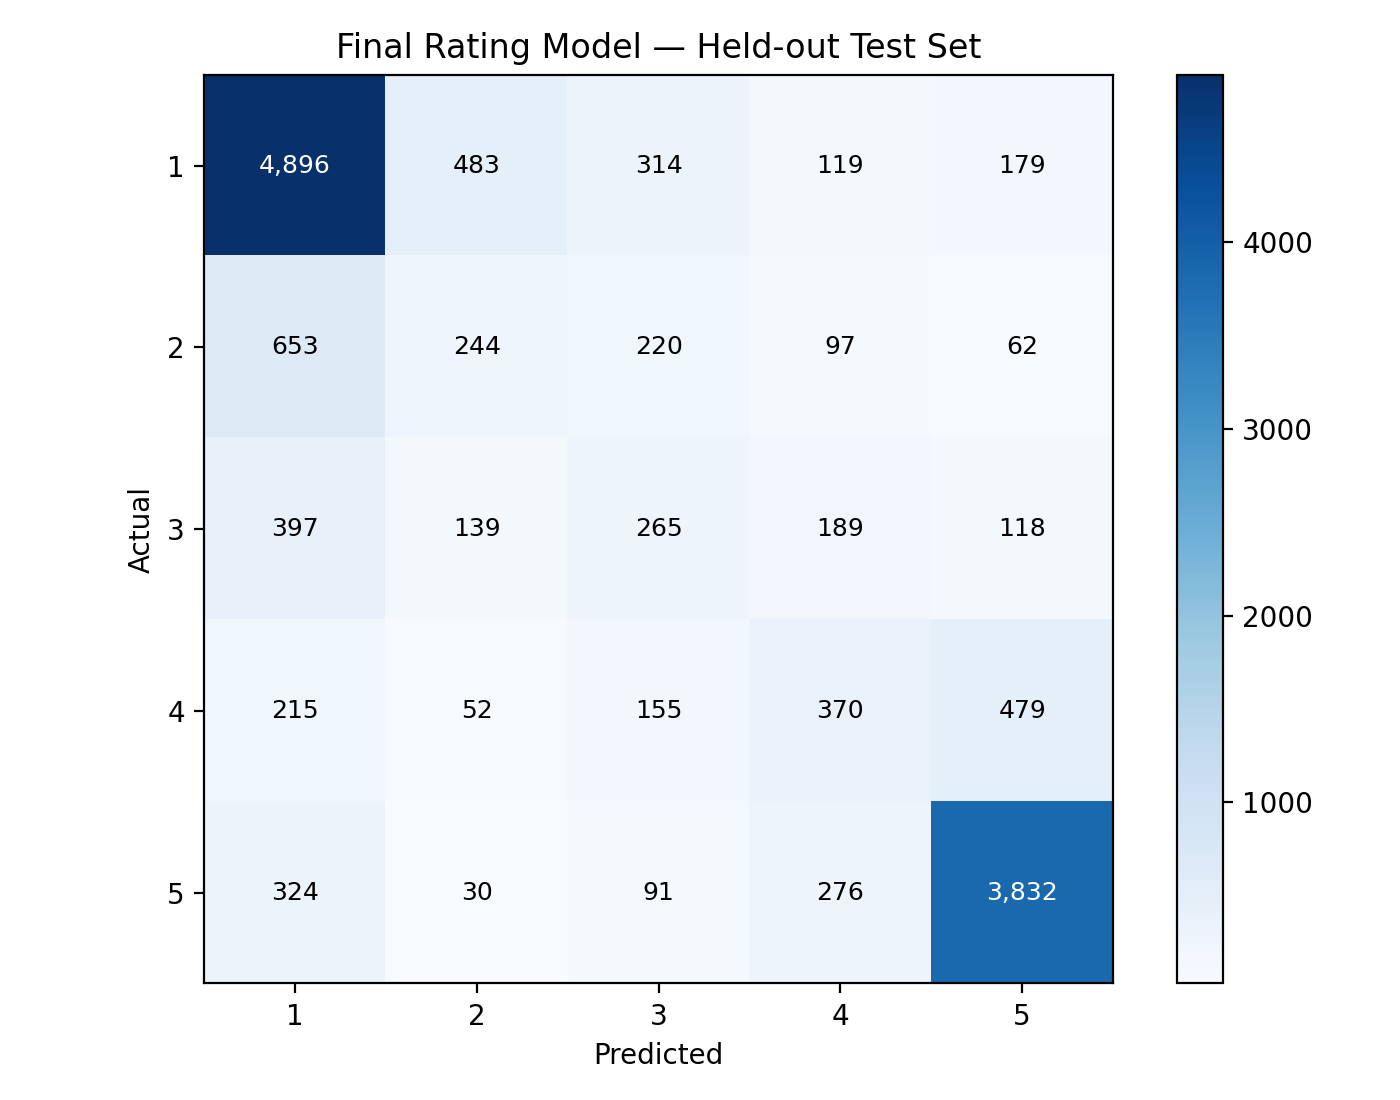

In [8]:
for title, image_name in [
    ('Sentiment confusion matrix', 'confusion_matrix_final_sentiment_model.png'),
    ('Rating confusion matrix', 'confusion_matrix_final_rating_model.png'),
]:
    figure = ROOT / 'reports/figures' / image_name
    assert figure.exists(), f'Missing figure: {figure}'
    print(title)
    display(Image(filename=str(figure), width=650))

## 8. Model-error patterns

For rating prediction, **MAE** captures distance between ordered classes (predicting 4 instead of 5 is less severe than predicting 1 instead of 5). The within-one-star score is also useful, but neither metric replaces inspection of individual classes.

In [9]:
actual_rating = df['rating'].to_numpy()[test_idx]
rating_error = np.abs(actual_rating - pred_rating.astype(int))
error_counts = pd.Series(rating_error).value_counts().sort_index().rename_axis('absolute_rating_error').reset_index(name='reviews')
display(error_counts)
print(f'Rating predictions within ±1 star: {(rating_error <= 1).mean():.2%}')
actual_sentiment = df['sentiment'].to_numpy()[test_idx]
sent_errors = pd.crosstab(pd.Series(actual_sentiment, name='actual'),
                          pd.Series(pred_sentiment, name='predicted'))
display(sent_errors)

,absolute_rating_error,reviews
0,0,9607
1,1,2594
2,2,1069
3,3,426
4,4,503


Rating predictions within ±1 star: 85.93%


predicted,Negative,Neutral,Positive
actual,,,
Negative,6214,667,386
Neutral,546,310,252
Positive,477,394,4953


## 9. Readme-ready final results

The numbers below come exclusively from the saved held-out test report. They should be used consistently in the README, Excel summary, and external project visuals.

In [10]:
display(saved[['final_model','accuracy','macro_f1','weighted_f1','mae','train_count','validation_count','test_count']])
print('Both prediction tasks were evaluated on the same held-out test partition.')

,final_model,accuracy,macro_f1,weighted_f1,mae,train_count,validation_count,test_count
task,,,,,,,,
sentiment,TF-IDF + LinearSVC,0.8083,0.6583,0.8140,NaN,42596,14199,14199
rating,CountVectorizer + Naive Bayes,0.6766,0.4800,0.6651,0.565,42596,14199,14199


Both prediction tasks were evaluated on the same held-out test partition.


## Interpretation and limitations

- **Sentiment classification:** The labels are proxies derived from the star ratings (1–2 Negative, 3 Neutral, 4–5 Positive), so they do not measure independent human sentiment annotations.
- **Rating prediction:** This is a five-class prediction problem; ordinal errors are additionally summarized by MAE and within-one-star accuracy.
- **Distribution:** Public app-store reviewers are self-selected, with substantially more 1-star and 5-star reviews than middle ratings.
- **Leakage:** Identical normalized cleaned texts are kept within one partition, but semantically similar paraphrases may still cross partitions.
- **Scope:** These are app-review models, not a deployed customer issue-tracking system. Common word patterns can suggest potential pain points but do not prove service causes.

**Reproduction:** Run `python src/collect_reviews.py`, `python src/preprocessing.py`, then `python src/train.py` from the project root; finally rerun this notebook to verify the saved outputs. Review availability may change on the public stores, so the exact dataset and scores can vary after recollection.